In [1]:
import math
import copy
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import DataLoader, Subset, ConcatDataset

from torchvision import datasets, transforms

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from IPython.display import clear_output

In [2]:
class TimeEmbed(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(1, dim),
            nn.SiLU(),
            nn.Linear(dim, dim)
        )

    def forward(self, t):
        return self.mlp(t[:, None])

class Block(nn.Module):
    def __init__(self, in_ch, out_ch, t_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.time_emb = nn.Linear(t_dim, out_ch)

    def forward(self, x, t):
        h = F.silu(self.conv1(x))
        h = h + self.time_emb(t)[:, :, None, None]
        h = F.silu(self.conv2(h))
        return h

class DoubleStandardClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        base = 32
        t_dim = 32

        self.time_embed = TimeEmbed(t_dim)

        self.down1 = Block(1, base, t_dim)
        self.down2 = Block(base, base * 2, t_dim)
        self.down3 = Block(base * 2, base * 2, t_dim)
        self.pool = nn.MaxPool2d(2)

        self.mid = Block(base * 2, base * 2, t_dim)

        self.out = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(base * 2, 2)
        )
        
    def forward(self, x, t):
        t = self.time_embed(t)

        d1 = self.down1(x, t)
        d2 = self.down2(self.pool(d1), t)
        d3 = self.down3(self.pool(d2), t)

        m = self.mid(d3, t)

        return self.out(m)

class SingleStandardClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        base = 22
        t_dim = 32

        self.time_embed = TimeEmbed(t_dim)

        self.down1 = Block(1, base, t_dim)
        self.down2 = Block(base, base * 2, t_dim)
        self.down3 = Block(base * 2, base * 2, t_dim)
        self.pool = nn.MaxPool2d(2)

        self.mid = Block(base * 2, base * 2, t_dim)

        self.out = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(base * 2, 2)
        )
        
    def forward(self, x, t):
        t = self.time_embed(t)

        d1 = self.down1(x, t)
        d2 = self.down2(self.pool(d1), t)
        d3 = self.down3(self.pool(d2), t)

        m = self.mid(d3, t)

        return self.out(m)

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, groups=8):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),  # GroupNorm is standard for Diffusion
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(groups, out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

class UNet(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            nn.Linear(1, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.input = DoubleConv(1, 64)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))

        self.bottleneck = DoubleConv(256, 512)

        self.up1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(384, 256)
        
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(192, 128)

        self.output = nn.Conv2d(128, 1, kernel_size=1)

        self.emb_down1 = nn.Linear(time_dim, 128)
        self.emb_down2 = nn.Linear(time_dim, 256)
        self.emb_up1 = nn.Linear(time_dim, 256)
        self.emb_up2 = nn.Linear(time_dim, 128)

    def forward(self, x, t):
        t = t.view(-1, 1) 
        emb = self.time_mlp(t)
        
        x1 = self.input(x)
        
        x2 = self.down1(x1)
        x2 = x2 + self.emb_down1(emb)[:, :, None, None]
        
        x3 = self.down2(x2)
        x3 = x3 + self.emb_down2(emb)[:, :, None, None]

        x_mid = self.bottleneck(x3)

        x_up1 = self.up1(x_mid)
        x_up1 = torch.cat([x_up1, x2], dim=1)
        x_up1 = self.conv_up1(x_up1) 
        x_up1 = x_up1 + self.emb_up1(emb)[:, :, None, None]
        
        x_up2 = self.up2(x_up1)
        x_up2 = torch.cat([x_up2, x1], dim=1)
        x_up2 = self.conv_up2(x_up2)
        x_up2 = x_up2 + self.emb_up2(emb)[:, :, None, None]

        return self.output(x_up2)

class Classifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 64, 3, padding=1),
            nn.GroupNorm(16, 64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.1),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.GroupNorm(16, 128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.GroupNorm(16, 256),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.3),

            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )

        self.fc = nn.Linear(256, 30)

    def forward(self, x):
        x = self.features(x)
        return self.fc(x)

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

patternClassifier = SingleStandardClassifier().to(device)
clothesClassifier = SingleStandardClassifier().to(device)
doubleClassifier = DoubleStandardClassifier().to(device)
cls = Classifier().to(device)
uNet = UNet().to(device)

patternClassifier.eval()
clothesClassifier.eval()
doubleClassifier.eval()
cls.eval()
uNet.eval()

# doubleClassifier.load_state_dict(torch.load("single_dre.pth", map_location=device))
# clothesClassifier.load_state_dict(torch.load("duo_type_dre.pth", map_location=device))
# patternClassifier.load_state_dict(torch.load("duo_patt_dre.pth", map_location=device))

cls.load_state_dict(torch.load("fashion_pattern_mnist_cnn.pth", map_location=device))
uNet.load_state_dict(torch.load("diffusion.pth", map_location=device))

img_size = 28
batch_size = 128
epochs = 100
timesteps = 500

beta = torch.linspace(1e-4, 0.02, timesteps).to(device)
alpha = 1. - beta
alpha_bar = torch.cumprod(alpha, dim=0)

In [4]:
addition_whole = []
for s in [0.5]:
    # n_samples = 500
    n_samples = 500
    addition = []
    
    for j in range(5):
    # for j in range(1):
        # doubleClassifier.load_state_dict(torch.load(f"Training DRES/CloPat DRE/best_CloPat_{i}.pt", map_location=device))
        clothesClassifier.load_state_dict(torch.load(f"Training DRES/clothes DRE/best_clothes_{j}.pt", map_location=device))
        patternClassifier.load_state_dict(torch.load(f"Training DRES/pattern DRE/best_pattern_{j}.pt", map_location=device))
    
        addition_outputs = []
        with torch.no_grad():
            xt = torch.randn(n_samples, 1, img_size, img_size).to(device)
            
            for i in reversed(range(timesteps)):
                t = torch.tensor([i] * n_samples, device=device)
                
                eps_pred = uNet(xt, t.float() / timesteps)
                
                alpha_t = alpha[i]
                alpha_bar_t = alpha_bar[i]
                beta_t = beta[i]
        
                mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)
        
                with torch.enable_grad():
                    dre_xt = xt.detach().clone().requires_grad_(True)
                    
                    logits = clothesClassifier(dre_xt, t.float() / timesteps) 
                    log_probs = F.log_softmax(logits, dim=1)
                    
                    r = log_probs[:, 1] - log_probs[:, 0]
                    
                    pattern_guide_score = torch.autograd.grad(
                        outputs=r.sum(),
                        inputs=dre_xt
                    )[0]
    
                with torch.enable_grad():
                    dre_xt = xt.detach().clone().requires_grad_(True)
                    
                    logits = patternClassifier(dre_xt, t.float() / timesteps)
                    log_probs = F.log_softmax(logits, dim=1)
                    
                    r = log_probs[:, 1] - log_probs[:, 0]
                    
                    shape_guide_score = torch.autograd.grad(
                        outputs=r.sum(),
                        inputs=dre_xt
                    )[0]
                mean = mean + s * beta_t * (pattern_guide_score + shape_guide_score)
                
                if i > 0:
                    noise = torch.randn_like(xt)
                    xt = mean + torch.sqrt(beta_t) * noise
                else:
                    xt = mean
            print("s: {} complete", s)
            addition_outputs.append((s, xt))
        addition.append(addition_outputs)
    addition_whole.append((s, addition))

s: {} complete 0.5
s: {} complete 0.5
s: {} complete 0.5
s: {} complete 0.5
s: {} complete 0.5


(-0.5, 839.5, 27.5, -0.5)

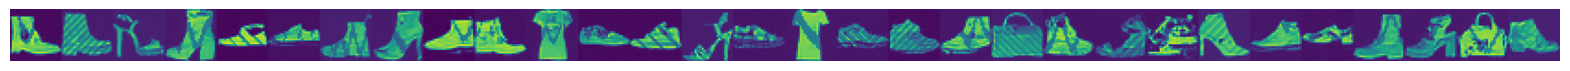

In [5]:
plt.figure(figsize=(20, 20))
plt.imshow(torch.cat([xt[i] for i in range(30)], dim=2).cpu().squeeze())
plt.axis('off')

In [6]:
double_whole = []
for s in [0.5]:
    # n_samples = 500
    n_samples = 500
    double = []
    
    for j in range(5):
        double_outputs = []
        doubleClassifier.load_state_dict(torch.load(f"Training DRES/CloPat DRE/best_CloPat_{j}.pt", map_location=device))
        # clothesClassifier.load_state_dict(torch.load(f"Training DRES/clothes DRE/best_clothes_{j}.pt", map_location=device))
        # patternClassifier.load_state_dict(torch.load(f"Training DRES/pattern DRE/best_pattern_{j}.pt", map_location=device))
    
        with torch.no_grad():
            xt = torch.randn(n_samples, 1, img_size, img_size).to(device)
            
            for i in reversed(range(timesteps)):
                t = torch.tensor([i] * n_samples, device=device)
                
                eps_pred = uNet(xt, t.float() / timesteps)
                
                alpha_t = alpha[i]
                alpha_bar_t = alpha_bar[i]
                beta_t = beta[i]
        
                mean = (xt - ((1 - alpha_t) / torch.sqrt(1 - alpha_bar_t)) * eps_pred) / torch.sqrt(alpha_t)
        
                with torch.enable_grad():
                    dre_xt = xt.detach().clone().requires_grad_(True)
                    
                    logits = doubleClassifier(dre_xt, t.float() / timesteps) 
                    log_probs = F.log_softmax(logits, dim=1)
                    
                    r = log_probs[:, 1] - log_probs[:, 0]
                    
                    double_guide_score = torch.autograd.grad(
                        outputs=r.sum(),
                        inputs=dre_xt
                    )[0]
    
                mean = mean + s * beta_t * double_guide_score
                
                if i > 0:
                    noise = torch.randn_like(xt)
                    xt = mean + torch.sqrt(beta_t) * noise
                else:
                    xt = mean
            print("s: {} complete", s)
            double_outputs.append((s, xt))
        double.append(double_outputs)
    double_whole.append((s, double))

s: {} complete 0.5
s: {} complete 0.5
s: {} complete 0.5
s: {} complete 0.5
s: {} complete 0.5


(-0.5, 839.5, 27.5, -0.5)

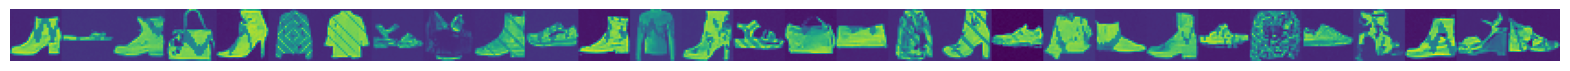

In [7]:
plt.figure(figsize=(20, 20))
plt.imshow(torch.cat([xt[i] for i in range(30)], dim=2).cpu().squeeze())
plt.axis('off')

In [8]:
# torch.save(double_whole, "DOUBLE_give_up.pt")
# torch.save(addition_whole, "ADDITION_give_up.pt")

In [9]:
# double_whole = torch.load("DOUBLE_give_up.pt")
# addition_whole = torch.load("ADDITION_give_up.pt")

In [10]:
def add_wave(img):
    amplitude, frequency, height, thickness, phase = random.randint(4, 10), random.randint(1, 4), random.randint(3, 20), random.randint(1, 3), random.uniform(0, 2 * math.pi)
    
    i = torch.arange(28)
    j = torch.arange(28)
    curve = height + amplitude * torch.cos(2 * math.pi * frequency * j / 28 + phase)
    
    rows = curve.round().long()
    x = torch.ones(28, 28)
    for d in range(-thickness, thickness + 1):
        r = (rows + d).clamp(0, 27)
        x[r, j] = 0.5
    return img * x

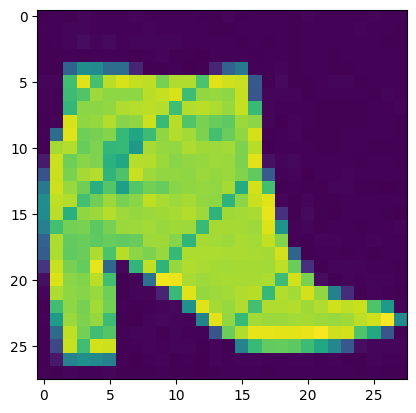

In [11]:
plt.imshow(addition[0][0][1][10][0].cpu())

In [12]:
test_dataset = datasets.FashionMNIST(
    root="./data", train=False, download=True, transform=None
)

test_base  = test_dataset.data.float().clone()[(test_dataset.targets == 5) | (test_dataset.targets == 7) | (test_dataset.targets == 9)] / 255.0

waves_test = []
for i in range(test_base.shape[0]):
    waves_test.append(add_wave(test_base[i]))
waves_test = torch.stack(waves_test)

real_images = transforms.Normalize((0.5,), (0.5,))(waves_test).unsqueeze(1)

In [13]:
(real_images[i][0]* 0.5 + 0.5).max()

tensor(0.9961)

(-0.5, 839.5, 27.5, -0.5)

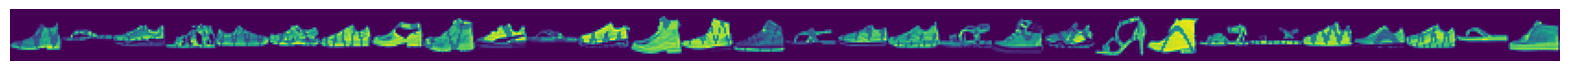

In [14]:
plt.figure(figsize=(20, 20))
plt.imshow(torch.cat([0.5 + 0.5 * real_images[i] for i in range(30)], dim=2).cpu().squeeze())
plt.axis('off')

In [15]:
def knn_radius(features, k=10):
    dists = torch.cdist(features, features)
    dists.fill_diagonal_(float("inf"))
    return dists.kthvalue(k, dim=1).values


def precision(real_feats, fake_feats, r_real):
    d = torch.cdist(fake_feats, real_feats)
    return (d <= r_real.unsqueeze(0)).any(dim=1).float().mean().item()


def recall(real_feats, fake_feats, r_fake):
    d = torch.cdist(real_feats, fake_feats)
    return (d <= r_fake.unsqueeze(0)).any(dim=1).float().mean().item()

In [16]:
_, double = double_whole[0]

In [17]:
_, double = double_whole[0]
_, addition = addition_whole[0]

In [18]:
experiments_double = []
cls.eval()
for experiment in double:
    metrics = []
    for s, fake_images in experiment:
        p, r = 0, 0
        for i in range(5):
            
            perm = torch.randperm(real_images.shape[0])[:500]
            
            real_feats = torch.nn.functional.normalize(cls.features(real_images[perm].cuda()))
            fake_feats = torch.nn.functional.normalize(cls.features(fake_images.clamp(-1, 1)))
            
            r_real = knn_radius(real_feats)
            r_fake = knn_radius(fake_feats)
            
            p += precision(real_feats, fake_feats, r_real)
            r += recall(real_feats, fake_feats, r_fake)

            # print(f"Guidance: {s}, Precision: {p:.4f}, Recall: {r:.4f}")
        p /= 5
        r /= 5
        metrics.append((s, p, r, (2 * p * r) / (p + r)))
    experiments_double.append(metrics)

In [19]:
experiments_double

[[(0.5, 0.3460000157356262, 0.9976000189781189, 0.5137981740791318)],
 [(0.5, 0.342000013589859, 0.9940000534057617, 0.5089042136615483)],
 [(0.5, 0.3940000176429749, 0.9948000311851501, 0.5644458756592227)],
 [(0.5, 0.18880001008510588, 0.9992000102996826, 0.31759085653974206)],
 [(0.5, 0.3752000153064728, 0.9972000360488892, 0.5452484039470181)]]

In [20]:
experiments_addition = []
cls.eval()
for experiment in addition:
    metrics = []
    for s, fake_images in experiment:
        p, r = 0, 0
        for i in range(5):
            
            perm = torch.randperm(real_images.shape[0])[:500]
            
            real_feats = torch.nn.functional.normalize(cls.features(real_images[perm].cuda()))
            fake_feats = torch.nn.functional.normalize(cls.features(fake_images.clamp(-1, 1)))
            
            r_real = knn_radius(real_feats)
            r_fake = knn_radius(fake_feats)
            
            p += precision(real_feats, fake_feats, r_real)
            r += recall(real_feats, fake_feats, r_fake)

            # print(f"Guidance: {s}, Precision: {p:.4f}, Recall: {r:.4f}")
        p /= 5
        r /= 5
        metrics.append((s, p, r, (2 * p * r) / (p + r)))
    experiments_addition.append(metrics)

In [21]:
experiments_addition

[[(0.5, 0.47960002422332765, 0.99000004529953, 0.6461676963051682)],
 [(0.5, 0.4956000328063965, 0.987600040435791, 0.659998096372336)],
 [(0.5, 0.45520002245903013, 0.9960000395774842, 0.6248335460358574)],
 [(0.5, 0.42640002965927126, 0.9948000311851501, 0.5969360324265104)],
 [(0.5, 0.4964000225067139, 0.9964000463485718, 0.662664767710525)]]

In [22]:
steps = torch.tensor(experiments_double)[0,:,0]
values = torch.tensor(experiments_double)[:,:,1:]
n = values.shape[0]
mean_exp = values.mean(dim=0)
std_exp = values.std(dim=0, unbiased=True)
sem_exp = std_exp / (n ** 0.5)

double_data = steps, mean_exp[:,2], sem_exp[:,0]
double_data

(tensor([0.5000]), tensor([0.4900]), tensor([0.0364]))

In [23]:
steps = torch.tensor(experiments_addition)[0,:,0]
values = torch.tensor(experiments_addition)[:,:,1:]
n = values.shape[0]
mean_exp = values.mean(dim=0)
std_exp = values.std(dim=0, unbiased=True)
sem_exp = std_exp / (n ** 0.5)

addition_data = steps, mean_exp[:,2], sem_exp[:,0]
addition_data

(tensor([0.5000]), tensor([0.6381]), tensor([0.0133]))

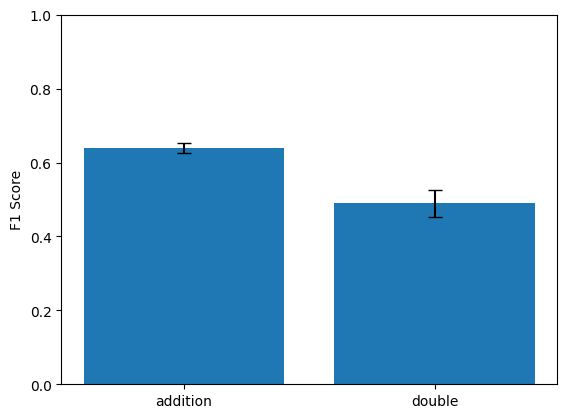

In [24]:
import matplotlib.pyplot as plt

means  = [addition_data[1].item(), double_data[1].item()]
errors = [addition_data[2].item(), double_data[2].item()]
labels = ["addition", "double"]

x = [0, 1]

plt.bar(x, means, yerr=errors, capsize=5)
plt.xticks(x, labels)
plt.ylim(0, 1)
plt.ylabel("F1 Score")

plt.show()


In [206]:
all_data = []
for i in range(4):
    _, double = double_whole[i]
    _, addition = addition_whole[i]

    
    experiments_double = []
    cls.eval()
    for experiment in double:
        metrics = []
        for s, fake_images in experiment:
            p, r = 0, 0
            for i in range(5):
                
                perm = torch.randperm(real_images.shape[0])[:500]
                
                real_feats = torch.nn.functional.normalize(cls.features(real_images[perm].cuda()))
                fake_feats = torch.nn.functional.normalize(cls.features(fake_images.clamp(-1, 1)))
                
                r_real = knn_radius(real_feats)
                r_fake = knn_radius(fake_feats)
                
                p += precision(real_feats, fake_feats, r_real)
                r += recall(real_feats, fake_feats, r_fake)
    
                # print(f"Guidance: {s}, Precision: {p:.4f}, Recall: {r:.4f}")
            p /= 5
            r /= 5
            metrics.append((s, p, r, (2 * p * r) / (p + r)))
        experiments_double.append(metrics)

        experiments_addition = []
        cls.eval()
        for experiment in addition:
            metrics = []
            for s, fake_images in experiment:
                p, r = 0, 0
                for i in range(5):
                    
                    perm = torch.randperm(real_images.shape[0])[:500]
                    
                    real_feats = torch.nn.functional.normalize(cls.features(real_images[perm].cuda()))
                    fake_feats = torch.nn.functional.normalize(cls.features(fake_images.clamp(-1, 1)))
                    
                    r_real = knn_radius(real_feats)
                    r_fake = knn_radius(fake_feats)
                    
                    p += precision(real_feats, fake_feats, r_real)
                    r += recall(real_feats, fake_feats, r_fake)
        
                    # print(f"Guidance: {s}, Precision: {p:.4f}, Recall: {r:.4f}")
                p /= 5
                r /= 5
                metrics.append((s, p, r, (2 * p * r) / (p + r)))
            experiments_addition.append(metrics)

        steps = torch.tensor(experiments_double)[0,:,0]
        values = torch.tensor(experiments_double)[:,:,1:]
        n = values.shape[0]
        mean_exp = values.mean(dim=0)
        std_exp = values.std(dim=0, unbiased=True)
        sem_exp = std_exp / (n ** 0.5)
        
        double_data = steps, mean_exp[:,2], sem_exp[:,0]


        steps = torch.tensor(experiments_addition)[0,:,0]
        values = torch.tensor(experiments_addition)[:,:,1:]
        n = values.shape[0]
        mean_exp = values.mean(dim=0)
        std_exp = values.std(dim=0, unbiased=True)
        sem_exp = std_exp / (n ** 0.5)
        
        addition_data = steps, mean_exp[:,2], sem_exp[:,0]


    all_data.append((addition_data[0], ((addition_data[0], addition_data[1], addition_data[2]), (double_data[0], double_data[1], double_data[2]))))

C:\Users\Sam\AppData\Local\Temp\ipykernel_25312\2758334638.py:61: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\ReduceOps.cpp:1839.)
  std_exp = values.std(dim=0, unbiased=True)


In [207]:
all_data

[(tensor([1.]),
  ((tensor([1.]), tensor([0.8161]), tensor([0.0087])),
   (tensor([1.]), tensor([0.6715]), tensor([0.0588])))),
 (tensor([3.]),
  ((tensor([3.]), tensor([0.8019]), tensor([0.0122])),
   (tensor([3.]), tensor([0.8133]), tensor([0.0764])))),
 (tensor([5.]),
  ((tensor([5.]), tensor([0.6502]), tensor([0.0210])),
   (tensor([5.]), tensor([0.8096]), tensor([0.0698])))),
 (tensor([7.]),
  ((tensor([7.]), tensor([0.6054]), tensor([0.0217])),
   (tensor([7.]), tensor([0.7966]), tensor([0.0674]))))]